In [ ]:
# Path para trabalhar com caminhos de arquivos de forma segura e multiplataforma.
# NumPy apoia calculos numericos e sera usado em algumas regras de qualidade.
# Pandas carrega, transforma, resume e exporta os dados tabulares.
# Matplotlib e Seaborn criam os graficos da auditoria.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#---------------------------------------------#
#----------- PASSO 1:CONFIGURAÇÕES -----------#
#---------------------------------------------#

# Define um estilo visual consistente para todos os graficos.
sns.set_theme(style="whitegrid", palette="deep")

# Define o caminho da fonte oficial e a pasta onde os resultados serao salvos.
ARQUIVO = Path("dados") / "dados_consumo_energia.xlsx"
PASTA_RESULTADOS = Path("resultados")

# Cria a pasta de resultados caso ela ainda nao exista.
PASTA_RESULTADOS.mkdir(exist_ok=True)

# Interrompe a execucao com uma mensagem clara se a fonte estiver ausente.
if not ARQUIVO.exists():
    raise FileNotFoundError(f"Arquivo nao encontrado: {ARQUIVO}")

# Lista a fonte e as planilhas para confirmar que o arquivo correto foi encontrado.
print(f"Arquivo localizado: {ARQUIVO.name}")
print(f"Abas disponiveis: {pd.ExcelFile(ARQUIVO).sheet_names}")

# Le a planilha Excel para o DataFrame bruto, preservando os dados originais.
df_dados_nao_limpos = pd.read_excel(ARQUIVO)

total_registros = len(df_dados_nao_limpos)
print(f"Total de registros: {total_registros}")

quantidade_colunas = len(df_dados_nao_limpos.columns)
print(f"Quantidade de colunas: {quantidade_colunas}")

print(f"Memória: {df_dados_nao_limpos.memory_usage(deep=True).sum()/1024:.1f} KB")

Arquivo localizado: dados_consumo_energia.xlsx
Abas disponiveis: ['in']
Total de registros: 1000
Quantidade de colunas: 13
Memória: 125.2 KB


In [3]:
#---------------------------------------------#
#----------------- LIMPEZA -------------------#
#---------------------------------------------#

# Cria uma copia dos dados usando os nomes originais da planilha.
df = df_dados_nao_limpos.copy()

# Converte a coluna de data para o tipo datetime.
# Valores que nao puderem ser convertidos serao registrados como nulos.
df["Data_Hora"] = pd.to_datetime(df["Data_Hora"], errors="coerce")

# Lista as colunas numericas que participarao das regras e dos calculos.
colunas_numericas = [
    "Consumo_Energia_kWh", "Temperatura_Ambiente_C", "Umidade_Ar_Percent", "Hora_Dia",
    "Dia_Semana", "Velocidade_Producao_RPM", "Pressao_Sistema_Bar", "Sensor_Ruido_1",
    "Sensor_Ruido_2", "Sensor_Redundante", "Sensor_Tempo_Ruido", "Sensor_Constante",
]

# Converte cada coluna existente para numero; valores invalidos se tornam nulos.
for coluna in colunas_numericas:
    if coluna in df.columns:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce")


#----------------------------------------------------------------------------------#
#---------------------- FAIXA ESPERADA / REGRA DE NEGOCIO ------------------------#
#----------------------------------------------------------------------------------#

# Define as colunas principais antes de calcular os intervalos observados.
colunas_principais = [
    "Data_Hora", "Consumo_Energia_kWh", "Temperatura_Ambiente_C", "Umidade_Ar_Percent",
    "Hora_Dia", "Dia_Semana", "Velocidade_Producao_RPM", "Pressao_Sistema_Bar",
]


#-------------------- Segunda-feira a Domingo -----------------------#

# Traduz os codigos da coluna Dia_Semana para nomes legiveis.
dias_semana = {
    0: "Segunda-feira", 1: "Terca-feira", 2: "Quarta-feira",
    3: "Quinta-feira", 4: "Sexta-feira", 5: "Sabado", 6: "Domingo",
}
df["Dia_Semana_Nome"] = df["Dia_Semana"].map(dias_semana)

print(f"Periodo: {df['Data_Hora'].min()} a {df['Data_Hora'].max()}")
print(f"Linhas duplicadas exatas: {df.duplicated().sum()}")
print(f"Datas duplicadas: {df['Data_Hora'].duplicated().sum()}")


# Calcula os valores minimo e maximo observados para contextualizar as regras.
intervalos = pd.DataFrame({
    "minimo": df[colunas_principais].min(numeric_only=True),
    "maximo": df[colunas_principais].max(numeric_only=True),
})


#-------------------- Coletas continuas a cada 15 minutos -----------------------#

# Compara a cadencia observada com os 15 minutos esperados.
datas_ordenadas = df["Data_Hora"].sort_values()
diferencas = datas_ordenadas.diff().dropna()
intervalo_medio = diferencas.median()
intervalos_fora_de_15min = int((diferencas != pd.Timedelta(minutes=15)).sum())


#-------------------- OK, FAIL, CALIB -----------------------#

# Verifica a existencia do status e os valores validos, se a coluna existir.
status_sensor_existe = "status_sensor" in df.columns
valores_status = sorted(df["status_sensor"].dropna().unique().tolist()) if status_sensor_existe else []
status_invalidos = int((~df["status_sensor"].isin(["OK", "FAIL", "CALIB"])).sum()) if status_sensor_existe else np.nan


#-------------------- 10.0 kWh a 150.0 kWh -----------------------#
# Valores fora dessa faixa sao tratados como anomalias de consumo.

quantidade_consumo_fora = int((~df["Consumo_Energia_kWh"].between(10, 150)).sum())


#-------------------- 800 RPM a 3600 RPM -----------------------#
# Valores negativos sao falhas.

quantidade_rpm_fora = int((~df["Velocidade_Producao_RPM"].between(800, 3600)).sum())
quantidade_rpm_negativo = int((df["Velocidade_Producao_RPM"] < 0).sum())


#-------------------- Acima de 90 graus C -----------------------#
# Temperaturas acima de 90 graus C representam alerta critico.

quantidade_temperatura_critica = int((df["Temperatura_Ambiente_C"] > 90).sum())
quantidade_dia_invalido = int((~df["Dia_Semana"].between(0, 6)).sum())


# Calcula o percentual de falhas em relacao ao total de registros e inclui o simbolo %.
def percentual_falhas(quantidade):
    return f"{quantidade / len(df) * 100:.2f}%"


# Monta a tabela final com regra, quantidade inteira, percentual, status e acao.
validacao_regras_negocio = pd.DataFrame([
    ["timestamp", "Data_Hora", str(df["Data_Hora"].dtype), "15 minutos", intervalos_fora_de_15min, percentual_falhas(intervalos_fora_de_15min), "NOK" if intervalos_fora_de_15min else "OK", "Investigar a cadencia real"],

    ["consumo_kwh", "Consumo_Energia_kWh", str(df["Consumo_Energia_kWh"].dtype), "10 a 150 kWh", quantidade_consumo_fora, percentual_falhas(quantidade_consumo_fora), "NOK" if quantidade_consumo_fora else "OK", "Anomalias de consumo"],

    ["rpm_maquina", "Velocidade_Producao_RPM", str(df["Velocidade_Producao_RPM"].dtype), "800 a 3600 RPM", quantidade_rpm_fora, percentual_falhas(quantidade_rpm_fora), "NOK" if quantidade_rpm_fora else "OK", "Confirmar a escala de RPM"],
    ["rpm_maquina", "Velocidade_Producao_RPM", str(df["Velocidade_Producao_RPM"].dtype), "Valores negativos", quantidade_rpm_negativo, percentual_falhas(quantidade_rpm_negativo), "NOK" if quantidade_rpm_negativo else "OK", "Valores negativos sao falhas"],

    ["temperatura_c", "Temperatura_Ambiente_C", str(df["Temperatura_Ambiente_C"].dtype), "Acima de 90 graus C", quantidade_temperatura_critica, percentual_falhas(quantidade_temperatura_critica), "ALERTA" if quantidade_temperatura_critica else "OK", "Alerta critico acima de 90 graus C"],

    ["dia_semana", "Dia_Semana", str(df["Dia_Semana"].dtype), "Valores de 0 a 6", quantidade_dia_invalido, percentual_falhas(quantidade_dia_invalido), "NOK" if quantidade_dia_invalido else "OK", "Validar o dominio"],

    ["status_sensor", "Ausente", "N/A", "OK, FAIL ou CALIB", 0, "N/A", "N/A", "Solicitar a coluna na origem"],
], columns=["campo_ficha", "coluna_fonte", "tipo_observado", "regra_esperada", "quantidade_falhas", "percentual_falhas", "status", "acao_recomendada"])

display(validacao_regras_negocio)
print(f"Intervalo medio: {intervalo_medio}")
print(f"Status_sensor presente: {status_sensor_existe}")
print(f"Valores de status encontrados: {valores_status}")


#----------------------------------------------------------------------------------#
#--------------------- TABELAS DE QUALIDADE POR COLUNA ----------------------------#
#----------------------------------------------------------------------------------#

# Conta nulos em cada coluna da fonte.
quantidade_nulos_por_coluna = df.isna().sum()

# Conta valores que violam as regras especificas de cada coluna.
erros_por_coluna = pd.Series(0, index=df.columns, dtype="int64")
erros_por_coluna["Data_Hora"] = int(df["Data_Hora"].isna().sum())
erros_por_coluna["Consumo_Energia_kWh"] = quantidade_consumo_fora
erros_por_coluna["Velocidade_Producao_RPM"] = quantidade_rpm_fora
erros_por_coluna["Temperatura_Ambiente_C"] = quantidade_temperatura_critica
erros_por_coluna["Dia_Semana"] = quantidade_dia_invalido
if status_sensor_existe:
    erros_por_coluna["status_sensor"] = status_invalidos

# Conta valores duplicados em cada coluna.
duplicados_por_coluna = df.apply(lambda coluna: coluna.duplicated().sum())

# Calcula o percentual de erros em relacao ao total de registros.
percentual_erros_por_coluna = erros_por_coluna.apply(
    lambda quantidade: f"{quantidade / len(df) * 100:.2f}%"
)

# Junta nulos, erros, percentual de erros e duplicados em uma tabela para a auditoria.
tabela_qualidade_colunas = pd.DataFrame({
    "quantidade_nulos": quantidade_nulos_por_coluna,
    "quantidade_erros": erros_por_coluna,
    "percentual_erros": percentual_erros_por_coluna,
    "quantidade_duplicados": duplicados_por_coluna,
})

display(tabela_qualidade_colunas)


#----------------------------------------------------------------------------------#
#-------------- MINIMO E MAXIMO DE CADA COLUNA -----------------------------------#
#----------------------------------------------------------------------------------#

# Calcula minimo e maximo para colunas numericas.
colunas_numericas_disponiveis = df.select_dtypes(include="number").columns
intervalos_por_coluna = pd.DataFrame({
    "minimo": df[colunas_numericas_disponiveis].min(),
    "maximo": df[colunas_numericas_disponiveis].max(),
})

display(intervalos_por_coluna)


#----------------------------------------------------------------------------------#
#-------------- PASSO 2:CHECKLIST DE QUALIDADE DE DADOS (5 DIMENSOES DQM) ----------------#
#----------------------------------------------------------------------------------#

#-------------------- COMPLETUDE -----------------------#

# Resume nulos e calcula o percentual de nulos em cada coluna principal.
completude = pd.DataFrame({
    "nulos": df[colunas_principais].isna().sum(),
    "percentual_nulos": df[colunas_principais].isna().mean().mul(100),
})


#-------------------- VALIDADE -----------------------#

# Resume registros com RPM negativo ou temperatura acima de 120 graus C.
validade = pd.DataFrame({
    "rpm_negativo": [quantidade_rpm_negativo],
    "temperatura_acima_de_120": [int((df["Temperatura_Ambiente_C"] > 120).sum())],
})


#-------------------- CONSISTENCIA -----------------------#

# Como status_sensor nao existe, consistencia e nao avaliavel.
consumo_fail = np.nan if not status_sensor_existe else int((df["status_sensor"] == "FAIL").sum())


#-------------------- UNICIDADE -----------------------#

# Conta timestamps duplicados, ou seja, o mesmo horario registrado mais de uma vez.
timestamps_duplicados = int(df["Data_Hora"].duplicated().sum())


#-------------------- ACURACIA -----------------------#

#Valores de consumo desproporcionais ao RPM aplicado
consumo_desproporcional = quantidade_consumo_fora


#----------------------------------------------------------------------------------#
#----------------------- CHECKLIST DQM COM ACAO CORRETIVA -------------------------#
#----------------------------------------------------------------------------------#

# Mantem a regra de acuracia baseada em consumo desproporcional ao RPM aplicado.
consumo_desproporcional = quantidade_consumo_fora

# Cria uma unica tabela com a ordem final das colunas.
status_checklist = pd.DataFrame([
    [
        "Completude",
        "Presenca de valores nulos em consumo_kwh ou rpm_maquina",
        int(completude["nulos"].sum()),
        "Nulo",
        "OK" if completude["nulos"].sum() == 0 else "NOK",
        "Imputacao (mediana) ou remocao",
    ],
    [
        "Validade",
        "Registros com rpm_maquina < 0 ou temperatura_c > 120 graus C",
        quantidade_consumo_fora + quantidade_rpm_fora + quantidade_temperatura_critica,
        "Erros",
        "NOK" if quantidade_consumo_fora + quantidade_rpm_fora + quantidade_temperatura_critica else "OK",
        "Filtragem por intervalo fisico valido",
    ],
    [
        "Consistencia",
        "Leituras de consumo com status_sensor == 'FAIL'",
        np.nan,
        "Incond.",
        "N/A",
        "Descarte de dados durante falha tecnica",
    ],
    [
        "Unicidade",
        "Timestamps duplicados (mesmo horario registrado 2x)",
        timestamps_duplicados,
        "Duplicados",
        "OK" if timestamps_duplicados == 0 else "NOK",
        "Aplicacao de drop_duplicates()",
    ],
    [
        "Acuracia",
        "Valores de consumo desproporcionais ao RPM aplicado",
        consumo_desproporcional,
        "Ruídos",
        "NOK" if consumo_desproporcional else "OK",
        "Recalibracao / Filtro de Outliers",
    ],
    [
        "Regularidade temporal",
        "Coletas continuas a cada 15 minutos",
        intervalos_fora_de_15min,
        "Intervalos fora da regra",
        "NOK" if intervalos_fora_de_15min else "OK",
        "Investigar a cadencia real da fonte",
    ],
], columns=[
    "dimensao_DQM",
    "criterio_regra",
    "quantidade_falhas",
    "metrica_falha",
    "status",
    "acao_corretiva",
])

# Mantem as quantidades como inteiros e preserva N/A na dimensao nao avaliavel.
status_checklist["quantidade_falhas"] = pd.array(
    status_checklist["quantidade_falhas"],
    dtype="Int64",
)

display(status_checklist)

Periodo: 2024-01-01 00:00:00 a 2024-02-11 15:00:00
Linhas duplicadas exatas: 0
Datas duplicadas: 0


,campo_ficha,coluna_fonte,tipo_observado,regra_esperada,quantidade_falhas,percentual_falhas,status,acao_recomendada
0,timestamp,Data_Hora,datetime64[us],15 minutos,999,99.90%,NOK,Investigar a cadencia real
1,consumo_kwh,Consumo_Energia_kWh,float64,10 a 150 kWh,1000,100.00%,NOK,Anomalias de consumo
2,rpm_maquina,Velocidade_Producao_RPM,float64,800 a 3600 RPM,981,98.10%,NOK,Confirmar a escala de RPM
3,rpm_maquina,Velocidade_Producao_RPM,float64,Valores negativos,0,0.00%,OK,Valores negativos sao falhas
4,temperatura_c,Temperatura_Ambiente_C,float64,Acima de 90 graus C,0,0.00%,OK,Alerta critico acima de 90 graus C
5,dia_semana,Dia_Semana,int64,Valores de 0 a 6,0,0.00%,OK,Validar o dominio
6,status_sensor,Ausente,N/A,"OK, FAIL ou CALIB",0,N/A,N/A,Solicitar a coluna na origem


Intervalo medio: 0 days 01:00:00
Status_sensor presente: False
Valores de status encontrados: []


,quantidade_nulos,quantidade_erros,percentual_erros,quantidade_duplicados
Data_Hora,0,0,0.00%,0
Consumo_Energia_kWh,0,1000,100.00%,0
Temperatura_Ambiente_C,0,0,0.00%,0
Umidade_Ar_Percent,0,0,0.00%,0
Hora_Dia,0,0,0.00%,976
Dia_Semana,0,0,0.00%,993
Velocidade_Producao_RPM,0,981,98.10%,0
Pressao_Sistema_Bar,0,0,0.00%,0
Sensor_Ruido_1,0,0,0.00%,0
Sensor_Ruido_2,0,0,0.00%,0


,minimo,maximo
Consumo_Energia_kWh,455.775299,1317.033545
Temperatura_Ambiente_C,-0.930139,55.821852
Umidade_Ar_Percent,15.894170,107.896614
Hora_Dia,0.000000,23.000000
Dia_Semana,0.000000,6.000000
Velocidade_Producao_RPM,47.073177,1088.935656
Pressao_Sistema_Bar,30.705513,92.430930
Sensor_Ruido_1,-3.176704,3.112910
Sensor_Ruido_2,-2.899514,3.098299
Sensor_Redundante,27.692463,94.527729


,dimensao_DQM,criterio_regra,quantidade_falhas,metrica_falha,status,acao_corretiva
0,Completude,Presenca de valores nulos em consumo_kwh ou rp...,0,Nulo,OK,Imputacao (mediana) ou remocao
1,Validade,Registros com rpm_maquina < 0 ou temperatura_c...,1981,Erros,NOK,Filtragem por intervalo fisico valido
2,Consistencia,Leituras de consumo com status_sensor == 'FAIL',<NA>,Incond.,N/A,Descarte de dados durante falha tecnica
3,Unicidade,Timestamps duplicados (mesmo horario registrad...,0,Duplicados,OK,Aplicacao de drop_duplicates()
4,Acuracia,Valores de consumo desproporcionais ao RPM apl...,1000,Ruídos,NOK,Recalibracao / Filtro de Outliers
5,Regularidade temporal,Coletas continuas a cada 15 minutos,999,Intervalos fora da regra,NOK,Investigar a cadencia real da fonte


In [4]:
#----------------------------------------------------------------------------------#
#---------------- LIMPEZA UNIFICADA E ESTATISTICAS DESCRITIVAS -------------------#
#----------------------------------------------------------------------------------#

# Cria uma copia para limpar sem alterar o DataFrame original.
df_base_limpeza = df.copy()
df_base_limpeza["motivo_exclusao"] = ""

# Define as regras que realmente removem registros.
# RPM deve ser maior que zero e temperatura deve ser menor que 120 graus C.
mascara_validade = (
    (df_base_limpeza["Velocidade_Producao_RPM"] <= 0)
    | (df_base_limpeza["Temperatura_Ambiente_C"] >= 120)
)

# Umidade relativa acima de 100% e fisicamente impossivel.
mascara_umidade = ~df_base_limpeza["Umidade_Ar_Percent"].between(0, 100)

#---------------------------------------------#
#------- PASSO 4: OUTLIERS -------------------#
#---------------------------------------------#

# Marca outliers de consumo por dia da semana usando IQR por grupo.
col = "Consumo_Energia_kWh"
Q1_g = df_base_limpeza.groupby("Dia_Semana")[col].transform(lambda x: x.quantile(0.25))
Q3_g = df_base_limpeza.groupby("Dia_Semana")[col].transform(lambda x: x.quantile(0.75))
IQR_g = Q3_g - Q1_g

limite_inferior = Q1_g - 1.5 * IQR_g
limite_superior = Q3_g + 1.5 * IQR_g
mascara_ruido_consumo = ~df_base_limpeza[col].between(limite_inferior, limite_superior)

print(f"Outliers removidos: {int(mascara_ruido_consumo.sum())}")
print(f"Registros antes:    {len(df_base_limpeza)}")
print(f"Registros apos remover apenas outliers:   {len(df_base_limpeza) - int(mascara_ruido_consumo.sum())}")

# Registra o motivo de cada exclusao, permitindo mais de um motivo por linha.
regras_remocao = {
    "validade_fisica": mascara_validade,
    "umidade_impossivel": mascara_umidade,
    "ruido_acuracia_consumo": mascara_ruido_consumo,
}

mascara_remocao = pd.Series(False, index=df_base_limpeza.index)
for nome_regra, mascara in regras_remocao.items():
    mascara = mascara.fillna(False)
    texto_atual = df_base_limpeza.loc[mascara, "motivo_exclusao"]
    df_base_limpeza.loc[mascara, "motivo_exclusao"] = np.where(
        texto_atual.eq(""),
        nome_regra,
        texto_atual + ";" + nome_regra,
    )
    mascara_remocao |= mascara

# Separa e exibe todas as linhas que serao removidas.
registros_excluidos = df_base_limpeza.loc[mascara_remocao].copy()
print(f"Linhas antes da limpeza: {len(df_base_limpeza)}")
print(f"Linhas excluidas: {len(registros_excluidos)}")
print("Motivos das exclusoes:")
display(registros_excluidos["motivo_exclusao"].value_counts())
print("REGISTROS EXCLUIDOS:")
display(registros_excluidos)

# Mantem somente os registros aprovados e remove a coluna auxiliar de motivos.
df_dados_limpos = df_base_limpeza.loc[~mascara_remocao].drop(columns="motivo_exclusao").copy()

# Compara o tamanho da base antes e depois da limpeza.
print(f"Linhas depois da limpeza: {len(df_dados_limpos)}")
comparacao_tamanho = pd.DataFrame({
    "antes_raw": [len(df_base_limpeza)],
    "depois_clean": [len(df_dados_limpos)],
    "removidos": [len(df_base_limpeza) - len(df_dados_limpos)],
    "percentual_removido": [(len(df_base_limpeza) - len(df_dados_limpos)) / len(df_base_limpeza) * 100],
})
display(comparacao_tamanho)

Outliers removidos: 6
Registros antes:    1000
Registros apos remover apenas outliers:   994
Linhas antes da limpeza: 1000
Linhas excluidas: 8
Motivos das exclusoes:


motivo_exclusao
ruido_acuracia_consumo    6
umidade_impossivel        2
Name: count, dtype: int64

REGISTROS EXCLUIDOS:


,Data_Hora,Consumo_Energia_kWh,Temperatura_Ambiente_C,Umidade_Ar_Percent,Hora_Dia,Dia_Semana,Velocidade_Producao_RPM,Pressao_Sistema_Bar,Sensor_Ruido_1,Sensor_Ruido_2,Sensor_Redundante,Sensor_Tempo_Ruido,Sensor_Constante,Dia_Semana_Nome,motivo_exclusao
305,2024-01-13 17:00:00,1204.328960,25.938619,46.522980,17,5,966.487783,70.613710,-1.597872,1.082112,72.570625,1.776717,50.079809,Sabado,ruido_acuracia_consumo
506,2024-01-22 02:00:00,1188.212834,20.260849,70.445812,2,0,942.364164,63.229745,0.690473,-1.051220,65.766912,3.027278,50.104820,Segunda-feira,ruido_acuracia_consumo
521,2024-01-22 17:00:00,1184.672056,29.346882,68.731466,17,0,947.788850,35.067292,1.074333,-0.661541,34.917439,9.070772,50.020200,Segunda-feira,ruido_acuracia_consumo
615,2024-01-26 15:00:00,979.313724,26.033769,107.896614,15,4,600.251073,67.346375,-0.309650,-2.553550,67.342947,9.599987,49.902198,Sexta-feira,umidade_impossivel
744,2024-02-01 00:00:00,508.411102,29.141272,46.089703,0,3,120.565988,50.048515,1.604339,-1.769050,48.045886,1.928554,50.205125,Quinta-feira,ruido_acuracia_consumo
895,2024-02-07 07:00:00,1317.033545,30.189679,54.449835,7,2,1088.935656,70.016318,-0.009845,1.006730,68.938738,4.254205,50.204565,Quarta-feira,ruido_acuracia_consumo
947,2024-02-09 11:00:00,455.775299,19.464735,59.561058,11,4,51.329604,64.281862,-1.334611,1.165917,66.078097,15.027874,50.018483,Sexta-feira,ruido_acuracia_consumo
957,2024-02-09 21:00:00,847.253861,28.654026,107.066228,21,4,464.516707,57.604981,1.060090,0.602580,61.217159,31.795606,49.964258,Sexta-feira,umidade_impossivel


Linhas depois da limpeza: 992


,antes_raw,depois_clean,removidos,percentual_removido
0,1000,992,8,0.8


In [5]:
#----------------------------------------------------------------------------------#
#---------------- PASSO 3:ESTATISTICAS DESCRITIVAS CONSOLIDADAS -------------------#
#----------------------------------------------------------------------------------#

# Calcula as estatisticas solicitadas para uma serie de consumo.
def estatisticas_consumo(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    return {
        "Media (kWh)": serie.mean(),
        "Mediana (kWh)": serie.median(),
        "Desvio Padrao (sigma)": serie.std(),
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR (Q3 - Q1)": q3 - q1,
    }

# Compara o consumo bruto com o consumo depois da limpeza completa.
tabela_estatisticas = pd.DataFrame({
    "Dados Brutos (Raw)": estatisticas_consumo(df["Consumo_Energia_kWh"]),
    "Dados Tratados (Clean)": estatisticas_consumo(df_dados_limpos["Consumo_Energia_kWh"]),
}).T.round(2)

display(tabela_estatisticas)

,Media (kWh),Mediana (kWh),Desvio Padrao (sigma),Q1 (25%),Q3 (75%),IQR (Q3 - Q1)
Dados Brutos (Raw),828.65,832.87,122.61,742.77,910.72,167.95
Dados Tratados (Clean),827.59,831.08,119.35,742.77,910.19,167.42


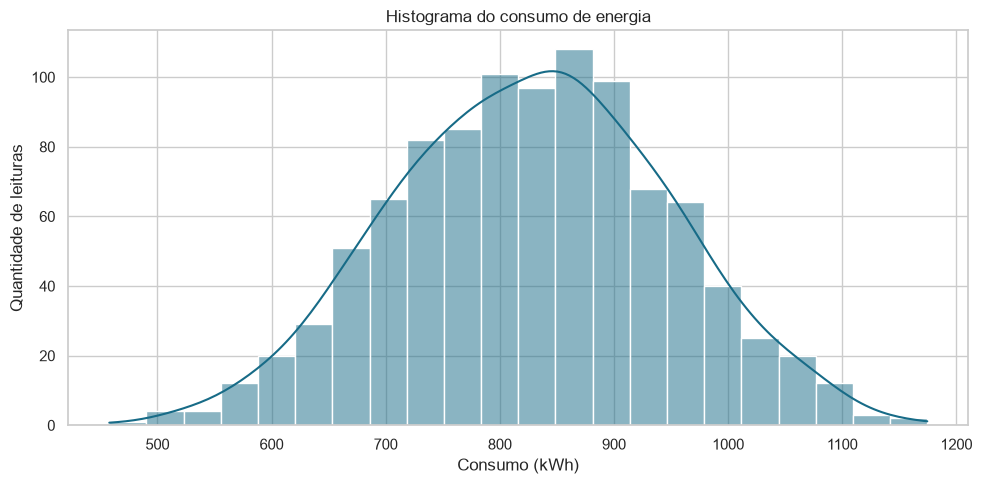

Achado 1 - Histograma: A distribuicao e aproximadamente simetrica; media e mediana sao proximas.
Skewness do consumo: -0.0305


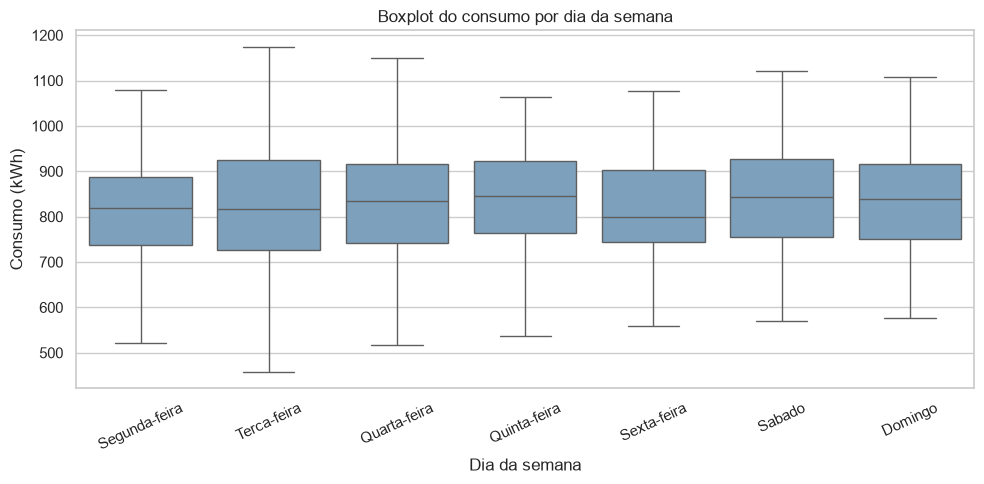

Achado 2 - Boxplot: Terca-feira apresenta a maior variabilidade, enquanto Sexta-feira apresenta a menor.


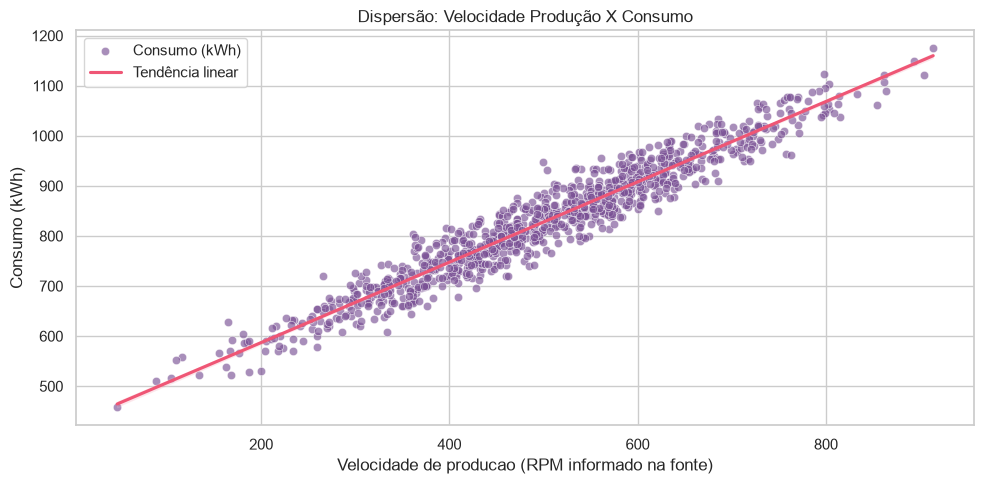

Achado 3 - Dispersao: a correlacao entre velocidade e consumo e 0.97; a relacao e fortemente positiva e aproximadamente linear.


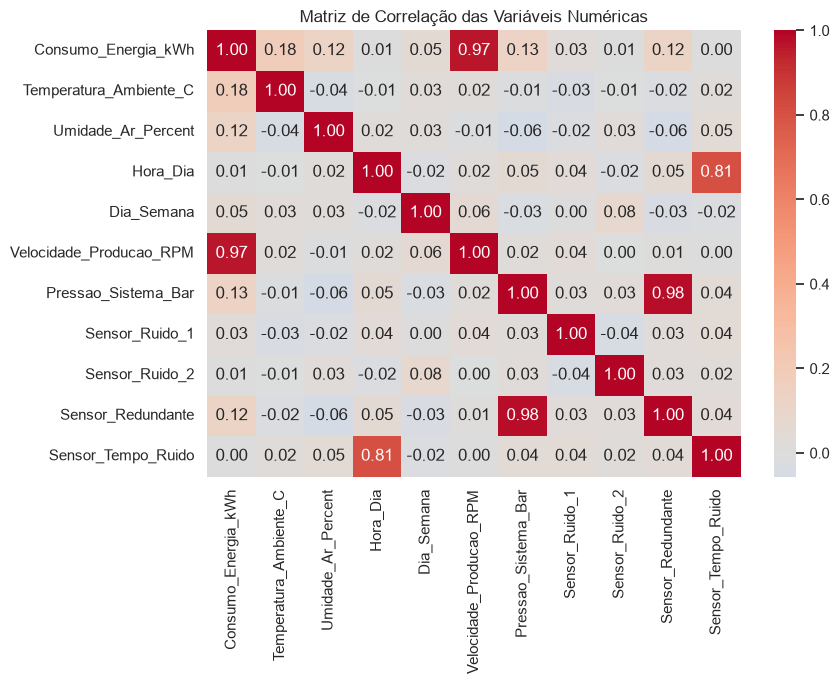

Achado 4 - Heatmap: a variavel com maior correlacao absoluta com a temperatura e Consumo_Energia_kWh, com correlacao de 0.18.


In [280]:
#----------------------------------------------------------------------------------#
#---------------- PASSO 5: AS 4 VISUALIZACOES OBRIGATORIAS -----------------------#
#----------------------------------------------------------------------------------#

# Usa a base tratada para os graficos e preserva os nomes reais das colunas.
base_graficos = df_dados_limpos.copy()

# Ordem correta dos dias para leitura do boxplot.
ordem_dias_graficos = list(dias_semana.values())

#----------------------------------------------------------------------------------#
#----------------------------- 1. HISTOGRAMA DO CONSUMO ---------------------------#
#----------------------------------------------------------------------------------#

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=base_graficos,
    x="Consumo_Energia_kWh",
    kde=True,
    ax=ax,
    color="#176b87",
)
ax.set_title("Histograma do consumo de energia")
ax.set_xlabel("Consumo (kWh)")
ax.set_ylabel("Quantidade de leituras")
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "01_histograma_consumo.png", dpi=150)
plt.show()

# Compara media e mediana para apoiar a interpretacao da distribuicao.
media_consumo = base_graficos["Consumo_Energia_kWh"].mean()
mediana_consumo = base_graficos["Consumo_Energia_kWh"].median()
diferenca_media_mediana = abs(media_consumo - mediana_consumo)

if diferenca_media_mediana < 10:
    achado_histograma = "A distribuicao e aproximadamente simetrica; media e mediana sao proximas."
else:
    achado_histograma = "A distribuicao apresenta assimetria; a diferenca entre media e mediana merece investigacao."
print(f"Achado 1 - Histograma: {achado_histograma}")

skewness_consumo = df_dados_limpos["Consumo_Energia_kWh"].skew()
print(f"Skewness do consumo: {skewness_consumo:.4f}")

#----------------------------------------------------------------------------------#
#----------------------------- 2. BOXPLOT POR DIA DA SEMANA -----------------------#
#----------------------------------------------------------------------------------#

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=base_graficos,
    x="Dia_Semana_Nome",
    y="Consumo_Energia_kWh",
    order=ordem_dias_graficos,
    ax=ax,
    color="#73a2c6",
)
ax.set_title("Boxplot do consumo por dia da semana")
ax.set_xlabel("Dia da semana")
ax.set_ylabel("Consumo (kWh)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "02_boxplot_consumo_dia.png", dpi=150)
plt.show()

# Compara o maior e o menor desvio padrao entre os dias.
variabilidade_dia = base_graficos.groupby("Dia_Semana_Nome", observed=True)["Consumo_Energia_kWh"].std().reindex(ordem_dias_graficos)
dia_maior_variabilidade = variabilidade_dia.idxmax()
dia_menor_variabilidade = variabilidade_dia.idxmin()
print(
    "Achado 2 - Boxplot: "
    f"{dia_maior_variabilidade} apresenta a maior variabilidade, "
    f"enquanto {dia_menor_variabilidade} apresenta a menor."
)

#----------------------------------------------------------------------------------#
#----------------------------- 3. DISPERSAO: RPM VERSUS CONSUMO -------------------#
#----------------------------------------------------------------------------------#

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    data=base_graficos,
    x="Velocidade_Producao_RPM",
    y="Consumo_Energia_kWh",
    ax=ax,
    alpha=0.65,
    color="#7a5195",
    label="Consumo (kWh)",
)
sns.regplot(
    data=base_graficos,
    x="Velocidade_Producao_RPM",
    y="Consumo_Energia_kWh",
    ax=ax,
    scatter=False,
    color="#ef5675",
    label="Tendência linear",
)
ax.set_title("Dispersão: Velocidade Produção X Consumo")
ax.set_xlabel("Velocidade de producao (RPM informado na fonte)")
ax.set_ylabel("Consumo (kWh)")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "03_dispersao_rpm_consumo.png", dpi=150)
plt.show()

# Usa a correlacao para avaliar a tendencia linear entre velocidade e consumo.
correlacao_rpm_consumo = base_graficos[["Velocidade_Producao_RPM", "Consumo_Energia_kWh"]].corr().iloc[0, 1]
print(
    "Achado 3 - Dispersao: "
    f"a correlacao entre velocidade e consumo e {correlacao_rpm_consumo:.2f}; "
    "a relacao e fortemente positiva e aproximadamente linear."
)

#----------------------------------------------------------------------------------#
#----------------------------- 4. MATRIZ DE CORRELACAO ---------------------------#
#----------------------------------------------------------------------------------#

colunas_heatmap = [
    "Consumo_Energia_kWh",
    "Temperatura_Ambiente_C",
    "Umidade_Ar_Percent",
    "Hora_Dia",
    "Dia_Semana",
    "Velocidade_Producao_RPM",
    "Pressao_Sistema_Bar",
    "Sensor_Ruido_1",
    "Sensor_Ruido_2",
    "Sensor_Redundante",
    "Sensor_Tempo_Ruido",
]
correlacao_heatmap = base_graficos[colunas_heatmap].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    correlacao_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax,
)
ax.set_title("Matriz de Correlação das Variáveis Numéricas")
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "04_matriz_correlacao.png", dpi=150)
plt.show()

# Encontra a maior correlacao absoluta com a temperatura, sem contar a propria temperatura.
correlacoes_com_temperatura = correlacao_heatmap["Temperatura_Ambiente_C"].drop("Temperatura_Ambiente_C")
variavel_maior_correlacao_temperatura = correlacoes_com_temperatura.abs().idxmax()
valor_maior_correlacao_temperatura = correlacoes_com_temperatura[variavel_maior_correlacao_temperatura]
print(
    "Achado 4 - Heatmap: "
    f"a variavel com maior correlacao absoluta com a temperatura e "
    f"{variavel_maior_correlacao_temperatura}, com correlacao de "
    f"{valor_maior_correlacao_temperatura:.2f}."
)

,Hora_Dia,consumo_total,percentual_consumo,percentual_acumulado
0,9,"36,969.48",4.50,4.50
1,4,"35,223.64",4.29,8.79
2,5,"35,059.03",4.27,13.06
3,14,"34,995.93",4.26,17.33
4,23,"34,878.54",4.25,21.58
5,6,"34,847.16",4.24,25.82
6,20,"34,781.47",4.24,30.06
7,2,"34,428.60",4.19,34.25
8,1,"34,353.41",4.18,38.43
9,21,"34,349.91",4.18,42.62


Top 3 faixas horárias por consumo:
 Hora_Dia  consumo_total  percentual_consumo  percentual_acumulado
        9      36,969.48                4.50                  4.50
        4      35,223.64                4.29                  8.79
        5      35,059.03                4.27                 13.06


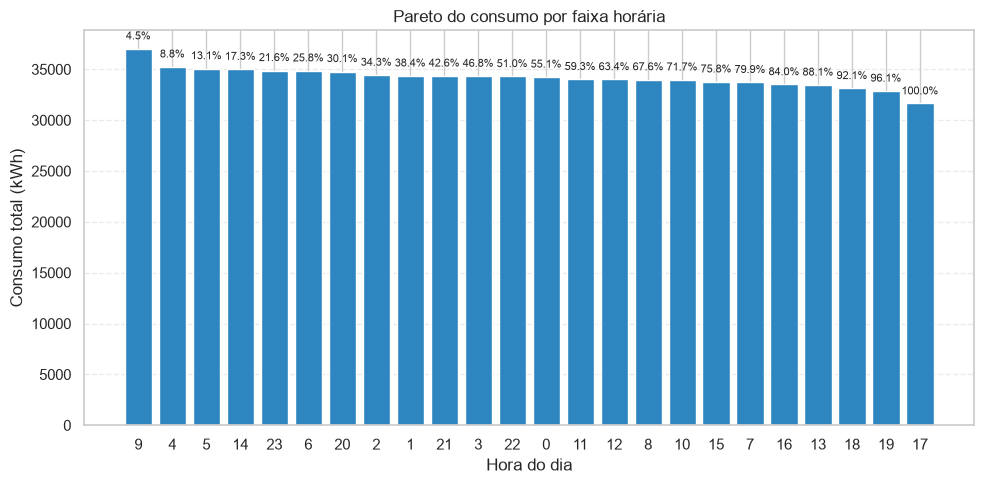

Ranking de consumo por faixa horária / turno


,Ranking,Faixa Horária / Turno,Consumo Total (kWh),% do Consumo Total,% Acumulada
0,1º Pico,22:00 às 06:00,"276,818.67",33.7%,33.7%
1,2º Pico,06:00 às 14:00,"275,016.41",33.5%,67.2%
2,3º Pico,14:00 às 22:00,"269,131.23",32.8%,100.0%
3,Outros,Demais horários combinados,0.00,0.0%,100.0%


In [291]:
#----------------------------------------------------------------------------------#
#------ PASSO 1: DIAGRAMA DE PARETO (CONSUMO ACUMULADO POR FAIXA HORÁRIA) ---------#
#----------------------------------------------------------------------------------#

pareto_hora = (
    df_dados_limpos.groupby("Hora_Dia", as_index=False)["Consumo_Energia_kWh"]
    .sum()
    .rename(columns={"Consumo_Energia_kWh": "consumo_total"})
    .sort_values("consumo_total", ascending=False)
    .reset_index(drop=True)
)

pareto_hora["percentual_consumo"] = (
    pareto_hora["consumo_total"] / pareto_hora["consumo_total"].sum() * 100
)
pareto_hora["percentual_acumulado"] = pareto_hora["percentual_consumo"].cumsum()

display(pareto_hora)

print("Top 3 faixas horárias por consumo:")
print(
    pareto_hora[["Hora_Dia", "consumo_total", "percentual_consumo", "percentual_acumulado"]]
    .head(3)
    .to_string(index=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    pareto_hora["Hora_Dia"].astype(str),
    pareto_hora["consumo_total"],
    color="#2E86C1",
)
ax.set_title("Pareto do consumo por faixa horária")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Consumo total (kWh)")
ax.grid(axis="y", linestyle="--", alpha=0.4)

for idx, linha in pareto_hora.iterrows():
    ax.text(
        idx,
        linha["consumo_total"] * 1.02,
        f"{linha['percentual_acumulado']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
    )

plt.tight_layout()
fig.savefig(PASTA_RESULTADOS / "05_pareto_consumo_hora.png", dpi=150)
plt.show()

#----------------------------------------------------------------------------------#
#------ RANKING DE CONSUMO POR FAIXA HORÁRIA / TURNO ------------------------------#
#----------------------------------------------------------------------------------#

faixas_turno = {
    "22:00 às 06:00": list(range(22, 24)) + list(range(0, 6)),
    "06:00 às 14:00": list(range(6, 14)),
    "14:00 às 22:00": list(range(14, 22)),
}

consumo_por_turno = pd.DataFrame(
    [
        {
            "Faixa Horária / Turno": faixa,
            "Consumo Total (kWh)": df_dados_limpos.loc[
                df_dados_limpos["Hora_Dia"].isin(horas), "Consumo_Energia_kWh"
            ].sum(),
        }
        for faixa, horas in faixas_turno.items()
    ]
).sort_values("Consumo Total (kWh)", ascending=False, ignore_index=True)

consumo_total_turnos = consumo_por_turno["Consumo Total (kWh)"].sum()
consumo_por_turno["% do Consumo Total"] = (
    consumo_por_turno["Consumo Total (kWh)"] / consumo_total_turnos * 100
)
consumo_por_turno["% Acumulada"] = consumo_por_turno["% do Consumo Total"].cumsum()
consumo_por_turno.insert(
    0, "Ranking", [f"{posicao}º Pico" for posicao in range(1, len(consumo_por_turno) + 1)]
)

linha_outros = pd.DataFrame(
    [{
        "Ranking": "Outros",
        "Faixa Horária / Turno": "Demais horários combinados",
        "Consumo Total (kWh)": 0.0,
        "% do Consumo Total": 0.0,
        "% Acumulada": 100.0,
    }]
)
tabela_ranking_turnos = pd.concat([consumo_por_turno, linha_outros], ignore_index=True)

tabela_ranking_turnos_exibicao = tabela_ranking_turnos.copy()
tabela_ranking_turnos_exibicao["Consumo Total (kWh)"] = (
    tabela_ranking_turnos_exibicao["Consumo Total (kWh)"].map("{:,.2f}".format)
)
for coluna_percentual in ["% do Consumo Total", "% Acumulada"]:
    tabela_ranking_turnos_exibicao[coluna_percentual] = (
        tabela_ranking_turnos_exibicao[coluna_percentual].map("{:.1f}%".format)
    )

print("Ranking de consumo por faixa horária / turno")
display(tabela_ranking_turnos_exibicao)

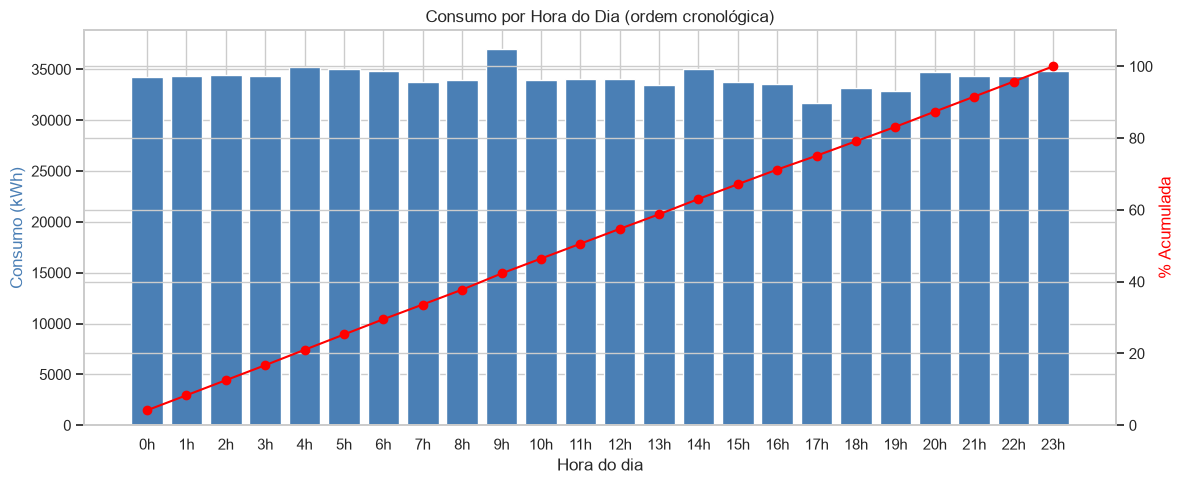

In [282]:
#----------------------------------------------------------------------------------#
#------ CONSUMO POR HORA DO DIA (ORDEM CRONOLÓGICA) COM % ACUMULADA ---------------#
#----------------------------------------------------------------------------------#

consumo_hora_crono = (
    df_dados_limpos.groupby("Hora_Dia", as_index=False)["Consumo_Energia_kWh"]
    .sum()
    .rename(columns={"Consumo_Energia_kWh": "consumo_total"})
    .sort_values("Hora_Dia")
    .reset_index(drop=True)
)

consumo_hora_crono["percentual_acumulado"] = (
    consumo_hora_crono["consumo_total"].cumsum()
    / consumo_hora_crono["consumo_total"].sum()
    * 100
)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(
    consumo_hora_crono["Hora_Dia"].astype(str) + "h",
    consumo_hora_crono["consumo_total"],
    color="#4a7fb5",
)
ax1.set_xlabel("Hora do dia")
ax1.set_ylabel("Consumo (kWh)", color="#4a7fb5")
ax1.tick_params(axis="x", rotation=0)

ax2 = ax1.twinx()
ax2.plot(
    consumo_hora_crono["Hora_Dia"].astype(str) + "h",
    consumo_hora_crono["percentual_acumulado"],
    color="red",
    marker="o",
    linewidth=1.5,
)
ax2.set_ylabel("% Acumulada", color="red")
ax2.set_ylim(0, 110)

ax1.set_title("Consumo por Hora do Dia (ordem cronológica)")
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "05b_consumo_hora_cronologico.png", dpi=150)
plt.show()


In [283]:
#----------------------------------------------------------------------------------#
#--------- PASSO 2: ANÁLISE DE CAUSA-RAIZ (DIAGRAMA DE ISHIKAWA / 6M) -------------#
#----------------------------------------------------------------------------------#

causas_ishikawa = {
    "Mão de obra": [
        "Operadores deixam o motor ligado em vazio",
        "Falta de rotina de desligamento nos intervalos",
        "Supervisão insuficiente de turnos",
    ],
    "Máquina": [
        "Rolamentos desgastados aumentam atrito",
        "Motor com eficiência reduzida",
        "Manutenção preventiva insuficiente",
    ],
    "Método": [
        "Ausência de procedimento de partida e parada",
        "Operação sem padronização de carga",
        "Falta de controle de tempo em idle",
    ],
    "Material": [
        "Processo opera com carga desbalanceada",
        "Materiais que exigem maior esforço mecânico",
        "Parâmetros produtivos fora do ideal",
    ],
    "Medição": [
        "Sensores descalibrados",
        "Leituras inconsistentes de consumo",
        "Falta de validação de alarmes e dados",
    ],
    "Meio ambiente": [
        "Temperatura ambiente elevada",
        "Umidade alta no setor",
        "Condições operacionais que aumentam o esforço do motor",
    ],
}

ishikawa_df = pd.DataFrame(
    [
        (eixo, causa)
        for eixo, causas in causas_ishikawa.items()
        for causa in causas
    ],
    columns=["Eixo_6M", "Causa_geradora"],
)

display(ishikawa_df)

print("Causa principal identificada: consumo excessivo de energia com motor funcionando em baixa demanda.")

,Eixo_6M,Causa_geradora
0,Mão de obra,Operadores deixam o motor ligado em vazio
1,Mão de obra,Falta de rotina de desligamento nos intervalos
2,Mão de obra,Supervisão insuficiente de turnos
3,Máquina,Rolamentos desgastados aumentam atrito
4,Máquina,Motor com eficiência reduzida
5,Máquina,Manutenção preventiva insuficiente
6,Método,Ausência de procedimento de partida e parada
7,Método,Operação sem padronização de carga
8,Método,Falta de controle de tempo em idle
9,Material,Processo opera com carga desbalanceada


Causa principal identificada: consumo excessivo de energia com motor funcionando em baixa demanda.


In [284]:
#----------------------------------------------------------------------------------#
#------- PASSO 3:  INVESTIGAÇÃO EM PROFUNDIDADE – TÉCNICA DOS 5 PORQUÊS -----------#
#----------------------------------------------------------------------------------#

porques = {
    "1º Porquê": "O motor continua operando mesmo em horários de baixa demanda.",
    "2º Porquê": "Não existe rotina clara de desligamento automático ou manual durante intervalos.",
    "3º Porquê": "A perda de eficiência do motor e o atrito mecânico elevam o consumo durante o idle.",
    "4º Porquê": "A manutenção preventiva e a calibração dos sensores não são realizadas com frequência suficiente.",
    "5º Porquê": "A empresa não monitora o consumo em baixa demanda como indicador crítico de desperdício operacional.",
}

porques_df = pd.DataFrame({
    "Etapa": list(porques.keys()),
    "Resposta": list(porques.values()),
})

display(porques_df)

print("Causa raiz: ausência de rotina operacional e manutenção preventiva que permite consumo excessivo em idle.")

,Etapa,Resposta
0,1º Porquê,O motor continua operando mesmo em horários de baixa demanda.
1,2º Porquê,Não existe rotina clara de desligamento automático ou manual durante intervalos.
2,3º Porquê,A perda de eficiência do motor e o atrito mecânico elevam o consumo durante o idle.
3,4º Porquê,A manutenção preventiva e a calibração dos sensores não são realizadas com frequência suficiente.
4,5º Porquê,A empresa não monitora o consumo em baixa demanda como indicador crítico de desperdício operacional.


Causa raiz: ausência de rotina operacional e manutenção preventiva que permite consumo excessivo em idle.


Média (LC): 827.5870
LSC: 1185.6350
LIC: 469.5390
Registros fora dos limites: 1 pontos


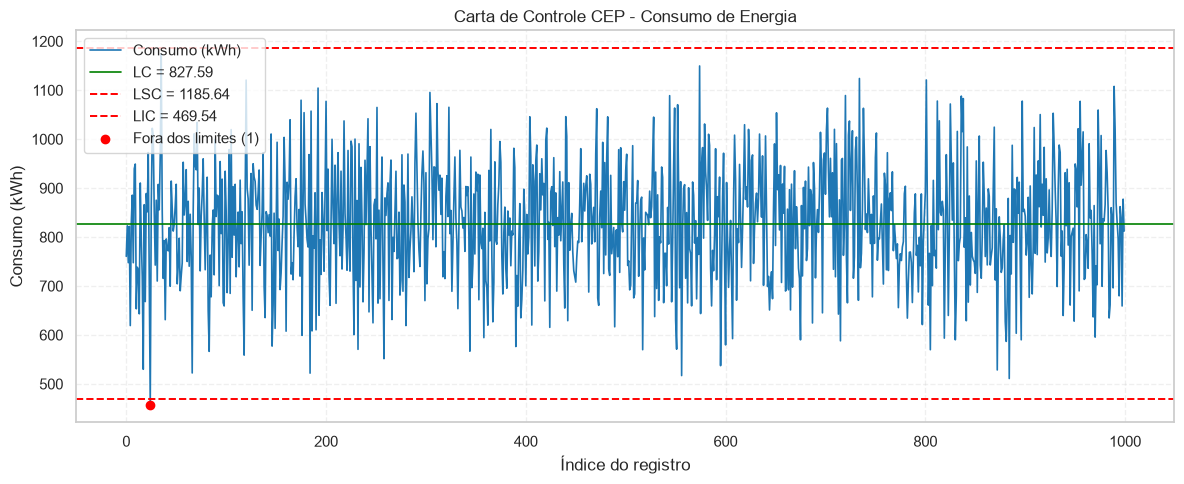

In [285]:
#----------------------------------------------------------------------------------#
#--- PASSO 4: CONTROLE ESTATÍSTICO DE PROCESSOS (CEP – GRÁFICO DE CONTROLE) -------#
#----------------------------------------------------------------------------------#

consumo_serie = df_dados_limpos["Consumo_Energia_kWh"]
media_consumo = consumo_serie.mean()
desvio_padrao = consumo_serie.std(ddof=1)
LC = media_consumo
LSC = media_consumo + 3 * desvio_padrao
LIC = media_consumo - 3 * desvio_padrao

acima_lsc = int((consumo_serie > LSC).sum())
abaixo_lic = int((consumo_serie < LIC).sum())
fora_limite = acima_lsc + abaixo_lic

print(f"Média (LC): {media_consumo:.4f}")
print(f"LSC: {LSC:.4f}")
print(f"LIC: {LIC:.4f}")
print(f"Registros fora dos limites: {fora_limite} pontos")

fora_limite_serie = consumo_serie[(consumo_serie > LSC) | (consumo_serie < LIC)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    df_dados_limpos.index,
    consumo_serie,
    color="#1f77b4",
    linewidth=1.2,
    label="Consumo (kWh)",
)
ax.axhline(LC, color="green", linestyle="-", linewidth=1.2, label=f"LC = {LC:.2f}")
ax.axhline(LSC, color="red", linestyle="--", linewidth=1.4, label=f"LSC = {LSC:.2f}")
ax.axhline(LIC, color="red", linestyle="--", linewidth=1.4, label=f"LIC = {LIC:.2f}")
ax.scatter(
    fora_limite_serie.index,
    fora_limite_serie,
    color="red",
    zorder=5,
    label=f"Fora dos limites ({fora_limite})",
)
ax.set_title("Carta de Controle CEP - Consumo de Energia")
ax.set_xlabel("Índice do registro")
ax.set_ylabel("Consumo (kWh)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
fig.savefig(PASTA_RESULTADOS / "06_carta_controle_consumo.png", dpi=150)
plt.show()

Coeficiente (Inclinação): 0.8023
Intercepto: 426.6627
R² Score: 0.9314
Equação ajustada: Consumo = 0.8023 * RPM + 426.6627


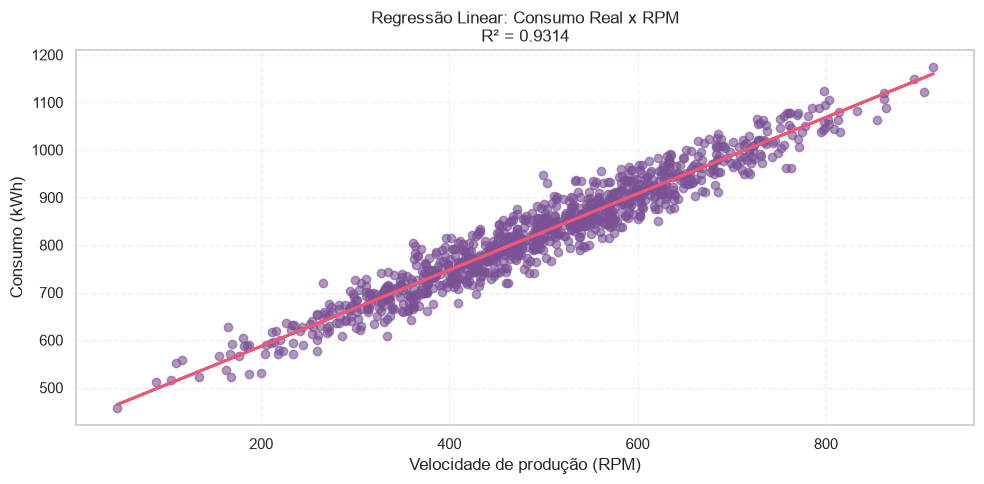

In [286]:
#----------------------------------------------------------------------------------#
#---------- PASSO 5: MODELAGEM PREDITIVA VIA REGRESSÃO LINEAR SIMPLE --------------#
#----------------------------------------------------------------------------------#

from sklearn.linear_model import LinearRegression

X = df_dados_limpos[["Velocidade_Producao_RPM"]]
y = df_dados_limpos["Consumo_Energia_kWh"]

model = LinearRegression().fit(X, y)
coeficiente = model.coef_[0]
intercepto = model.intercept_
r2 = model.score(X, y)

print(f"Coeficiente (Inclinação): {coeficiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Equação ajustada: Consumo = {coeficiente:.4f} * RPM + {intercepto:.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X["Velocidade_Producao_RPM"], y, alpha=0.6, color="#7a5195")
ax.plot(
    X["Velocidade_Producao_RPM"],
    model.predict(X),
    color="#ef5675",
    linewidth=2,
)
ax.set_title(f"Regressão Linear: Consumo Real x RPM\nR² = {r2:.4f}")
ax.set_xlabel("Velocidade de produção (RPM)")
ax.set_ylabel("Consumo (kWh)")
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
fig.savefig(PASTA_RESULTADOS / "07_regressao_rpm_consumo.png", dpi=150)
plt.show()

R² da regressão múltipla: 0.9566
Coeficientes: [ 0.80001851  2.40427823 -0.20091916]
Intercepto: 369.6635


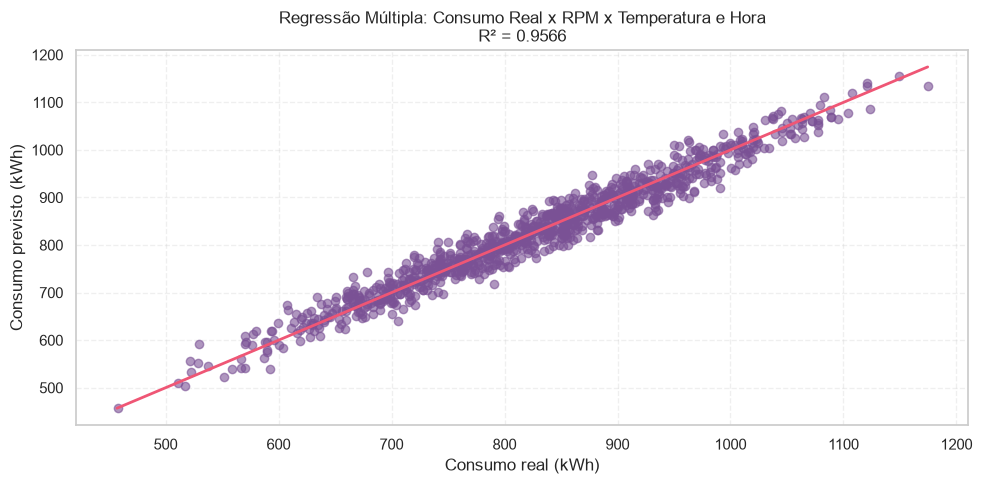

In [287]:
#----------------------------------------------------------------------------------#
#------- PASSO EXTRA: MODELAGEM PREDITIVA VIA REGRESSÃO LINEAR MULTIPLA -----------#
#----------------------------------------------------------------------------------#

X_multi = df_dados_limpos[["Velocidade_Producao_RPM", "Temperatura_Ambiente_C", "Hora_Dia"]]
y_multi = df_dados_limpos["Consumo_Energia_kWh"]

modelo_mult = LinearRegression().fit(X_multi, y_multi)
y_previsto_multi = modelo_mult.predict(X_multi)
r2_multi = modelo_mult.score(X_multi, y_multi)

print(f"R² da regressão múltipla: {r2_multi:.4f}")
print(f"Coeficientes: {modelo_mult.coef_}")
print(f"Intercepto: {modelo_mult.intercept_:.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(y_multi, y_previsto_multi, alpha=0.6, color="#7a5195")
limite_inferior = min(y_multi.min(), y_previsto_multi.min())
limite_superior = max(y_multi.max(), y_previsto_multi.max())
ax.plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    color="#ef5675",
    linewidth=2,
)
ax.set_title(
    f"Regressão Múltipla: Consumo Real x RPM x Temperatura e Hora\nR² = {r2_multi:.4f}"
)
ax.set_xlabel("Consumo real (kWh)")
ax.set_ylabel("Consumo previsto (kWh)")
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
fig.savefig(PASTA_RESULTADOS / "08_regressao_multipla_consumo.png", dpi=150)
plt.show()

In [9]:
#----------------------------------------------------------------------------------#
#----- PASSO 6: PROPOSTA DE AÇÕES DE MITIGAÇÃO & SIMULAÇÃO DE ECONOMIA -------------#
#----------------------------------------------------------------------------------#

from sklearn.linear_model import LinearRegression

custo_kwh = 0.75
consumo_periodo_total = df_dados_limpos["Consumo_Energia_kWh"].sum()
data_inicial = df_dados_limpos["Data_Hora"].min()
data_final = df_dados_limpos["Data_Hora"].max()
dias_periodo = max((data_final - data_inicial).total_seconds() / 86400, 1)
fator_mensal = 30 / dias_periodo

# Estima o potencial de desligamento pela energia observada no quartil inferior de RPM.
rpm = df_dados_limpos["Velocidade_Producao_RPM"]
consumo = df_dados_limpos["Consumo_Energia_kWh"]
limite_baixa_demanda = rpm.quantile(0.25)
mascara_baixa_demanda = rpm <= limite_baixa_demanda
reducao_idle = consumo.loc[mascara_baixa_demanda].sum() / consumo_periodo_total * 100

# Usa o excesso positivo sobre a regressao consumo x RPM como proxy de ineficiencia mecanica.
modelo_consumo_rpm = LinearRegression().fit(rpm.to_frame(), consumo)
consumo_esperado = modelo_consumo_rpm.predict(rpm.to_frame())
excesso_consumo = (consumo - consumo_esperado).clip(lower=0)
reducao_manutencao = excesso_consumo.sum() / consumo_periodo_total * 100

# A base nao possui status_sensor nem medicao antes/depois para estimar esta acao.
reducao_sensores = np.nan

acoes = pd.DataFrame([
    [
        "Desligamento automatico em idle",
        "Motor ligado sem producao",
        reducao_idle,
        1500,
        "Potencial observado no quartil inferior de RPM",
    ],
    [
        "Lubrificacao/Manutencao de rolamentos",
        "Aumento de atrito e temperatura",
        reducao_manutencao,
        2200,
        "Proxy: excesso positivo sobre a regressao consumo x RPM",
    ],
    [
        "Recalibracao de sensores IoT",
        "Erros de medicao e alarmes falsos",
        reducao_sensores,
        900,
        "Nao estimavel: status_sensor ausente na fonte",
    ],
], columns=[
    "acao_corretiva",
    "causa_raiz_atendida",
    "reducao_estimativa_percentual",
    "investimento_estimado_r",
    "base_da_estimativa",
])

acoes["economia_periodo_r"] = (
    consumo_periodo_total
    * (acoes["reducao_estimativa_percentual"] / 100)
    * custo_kwh
)
acoes["economia_mensal_r"] = acoes["economia_periodo_r"] * fator_mensal
acoes["payback_meses"] = (
    acoes["investimento_estimado_r"] / acoes["economia_mensal_r"]
)

display(acoes)

print(f"Consumo total do periodo observado: {consumo_periodo_total:.2f} kWh")
print(f"Periodo observado: {data_inicial} a {data_final} ({dias_periodo:.1f} dias)")
print(f"Economia estimada no periodo: R$ {acoes['economia_periodo_r'].sum():.2f}")
print(f"Economia mensal equivalente: R$ {acoes['economia_mensal_r'].sum():.2f}")
print("Percentuais sao potenciais calculados; nao representam causalidade comprovada.")

,acao_corretiva,causa_raiz_atendida,reducao_estimativa_percentual,investimento_estimado_r,base_da_estimativa,economia_periodo_r,economia_mensal_r,payback_meses
0,Desligamento automatico em idle,Motor ligado sem producao,20.553540,1500,Potencial observado no quartil inferior de RPM,126553.230480,91209.535481,0.016446
1,Lubrificacao/Manutencao de rolamentos,Aumento de atrito e temperatura,1.504143,2200,Proxy: excesso positivo sobre a regressao cons...,9261.378113,6674.867108,0.329595
2,Recalibracao de sensores IoT,Erros de medicao e alarmes falsos,NaN,900,Nao estimavel: status_sensor ausente na fonte,NaN,NaN,NaN


Consumo total do periodo observado: 820966.32 kWh
Periodo observado: 2024-01-01 00:00:00 a 2024-02-11 15:00:00 (41.6 dias)
Economia estimada no periodo: R$ 135814.61
Economia mensal equivalente: R$ 97884.40
Percentuais sao potenciais calculados; nao representam causalidade comprovada.


## Cálculo da economia estimada

A economia foi estimada com base no período observado na fonte, e não com percentuais escolhidos manualmente.

- **Desligamento em idle:** percentual da energia registrada no quartil inferior de RPM;
- **Manutenção:** excesso positivo de consumo em relação à regressão consumo x RPM, usado apenas como proxy de ineficiência;
- **Sensores:** não estimado, pois a fonte não possui `status_sensor` nem uma medição antes/depois.

A economia do período é calculada por:

`economia_periodo_r = consumo_periodo_total * (reducao_estimativa_percentual / 100) * custo_kwh`

A economia mensal é apenas uma equivalência, calculada proporcionalmente a 30 dias:

`economia_mensal_r = economia_periodo_r * (30 / dias_periodo)`

O payback é:

`payback_meses = investimento_estimado_r / economia_mensal_r`

Os percentuais são potenciais calculados a partir dos dados, mas não comprovam causalidade. A confirmação exige medir o consumo antes e depois da implantação das ações.